In [1]:
import sys
from pathlib import Path

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from torch import nn

In [3]:
sys.path.insert(0, "..")      # let the notebook find utils.py one folder up
from utils import load_checkpoint

In [4]:
RUNS = Path("..") / "runs"
run_dir = sorted(RUNS.glob("*_dummy_seed0"))[-1]   # the newest dummy run
print(run_dir)

../runs/2026-11-01_17-09-47_dummy_seed0


In [5]:
df = pd.read_csv(run_dir / "metrics.csv")
df.tail()

,epoch,train_loss,test_loss
16,160,7.167629,10.432714
17,170,7.122408,10.355591
18,180,7.078099,10.280056
19,190,7.034671,10.206071
20,200,6.992098,10.133595


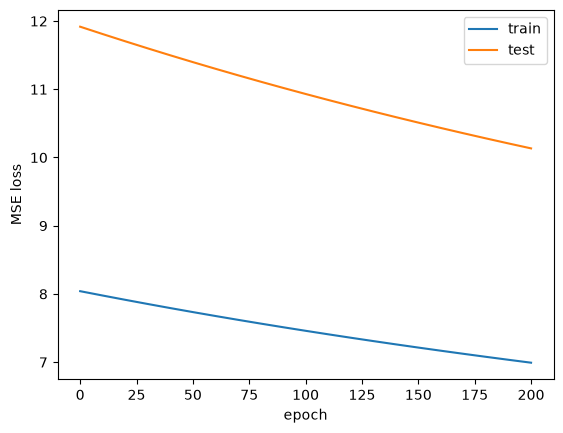

In [6]:
plt.plot(df["epoch"], df["train_loss"], label="train")
plt.plot(df["epoch"], df["test_loss"], label="test")
plt.xlabel("epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.show()

In [7]:
model = nn.Linear(in_features=2, out_features=1)
load_checkpoint(model, run_dir / "checkpoints" / "epoch_000200.pt")
print(model.weight, model.bias)

Parameter containing:
tensor([[ 0.5506, -0.1352]], requires_grad=True) Parameter containing:
tensor([-0.1224], requires_grad=True)
